In [1]:
import matplotlib.pyplot as plt
import numpy as np
from superfv.tools.stability_analysis.rk import compute_rk_amplification
from superfv.tools.stability_analysis.sd_advection import compute_solution_and_flux_point_coordinates

In [2]:
def plot_amplification_values(ax, p, k_values, cfl_values, scheme, rk, operator, coeff_D_lambda=None, **kwargs):
    data = []
    for cfl_val in cfl_values:
        coeff = dict(coeff_C=cfl_val, coeff_D=cfl_val if coeff_D_lambda is None else coeff_D_lambda(cfl_val))
        max_amplification = compute_rk_amplification(p, k_values, scheme=scheme, rk=rk, operator=operator, **coeff)
        data.append(max_amplification)
    y = np.array(data)

    ax.plot(cfl_values, y, **kwargs)

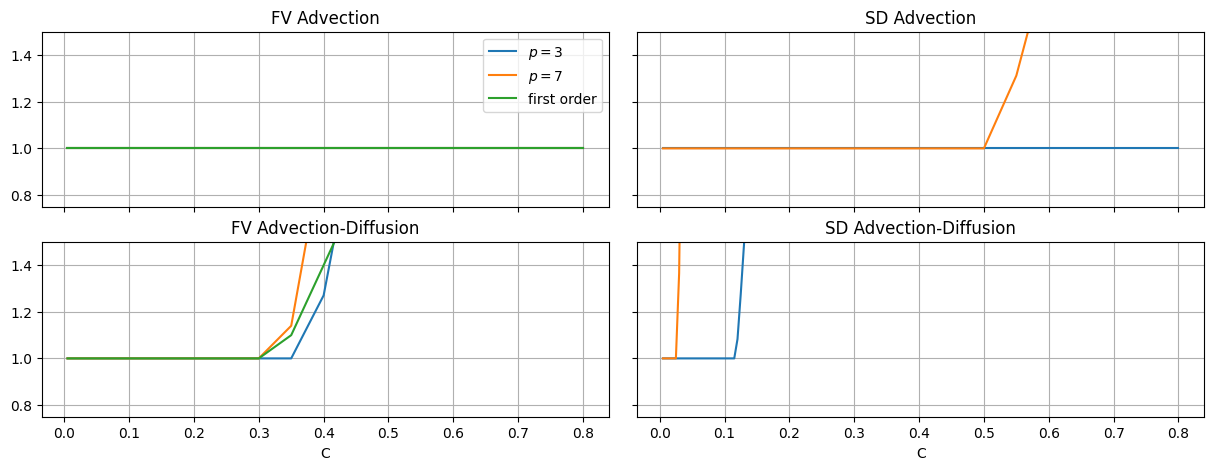

In [3]:
cfl_values = np.concatenate([np.arange(0.005, 0.205, 0.005), np.arange(0.25, 0.85, 0.05)])
# cfl_values = np.arange(0.2, 0.85, 0.05)
k_values = np.linspace(0, 2 * np.pi, 100)

fig, axs = plt.subplots(2, 2, sharex='col', sharey=True, figsize=(15, 5))
axs[0, 0].set_ylim(0.75, 1.5)
axs[1, 0].set_xlabel("C")
axs[1, 1].set_xlabel("C")

axs[0, 0].set_title("FV Advection")
plot_amplification_values(axs[0, 0], 3, k_values, cfl_values, "fv", "ssprk3", "advection", label=r"$p=3$")
plot_amplification_values(axs[0, 0], 7, k_values, cfl_values, "fv", "ssprk3", "advection", label=r"$p=7$")
plot_amplification_values(axs[0, 0], 0, k_values, cfl_values, "fv", "forward_euler", "advection", label=r"first order")

axs[1, 0].set_title("FV Advection-Diffusion")
plot_amplification_values(axs[1, 0], 3, k_values, cfl_values, "fv", "ssprk3", "both", label=r"$p=3$")
plot_amplification_values(axs[1, 0], 7, k_values, cfl_values, "fv", "ssprk3", "both", label=r"$p=7$")
plot_amplification_values(axs[1, 0], 0, k_values, cfl_values, "fv", "forward_euler", "both", label=r"first order")

axs[0, 1].set_title("SD Advection")
plot_amplification_values(axs[0, 1], 3, k_values, cfl_values, "sd", "ssprk3", "advection", label=r"$p=3$")
plot_amplification_values(axs[0, 1], 7, k_values, cfl_values, "sd", "ssprk3", "advection", label=r"$p=7$")

axs[1, 1].set_title("SD Advection-Diffusion")
plot_amplification_values(axs[1, 1], 3, k_values, cfl_values, "sd", "ssprk3", "both", label=r"$p=3$")
plot_amplification_values(axs[1, 1], 7, k_values, cfl_values, "sd", "ssprk3", "both", label=r"$p=7$")

axs[0, 0].legend()
for ax in axs.flat:
    ax.grid()

plt.subplots_adjust(hspace=0.2, wspace=0.05)

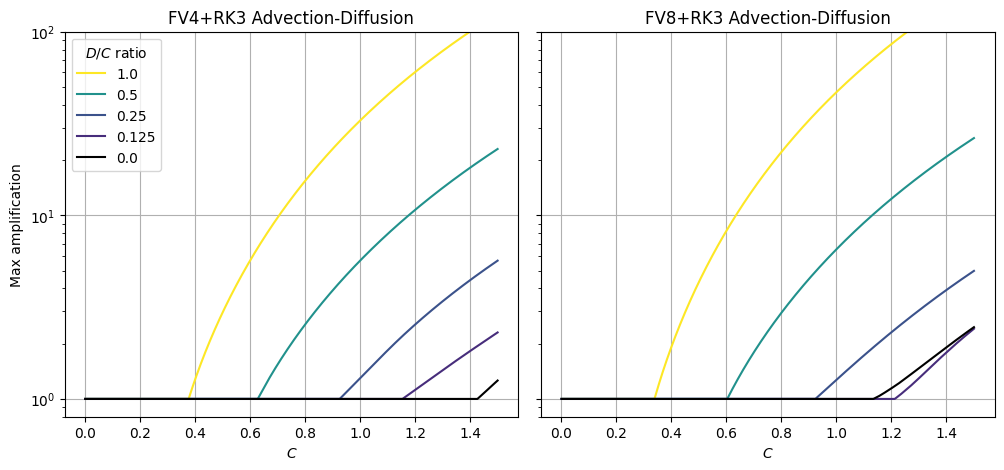

In [4]:
cfl_values = np.linspace(0.001, 1.5, 1000)
k_values = np.linspace(0, 2 * np.pi, 100)

fig, axs = plt.subplots(1, 2, sharex='col', sharey=True, figsize=(12, 5))
axs[0].set_title("FV4+RK3 Advection-Diffusion")
axs[1].set_title("FV8+RK3 Advection-Diffusion")
axs[0].set_xlabel(r"$C$")
axs[1].set_xlabel(r"$C$")
axs[0].set_ylabel("Max amplification")
axs[0].set_ylim(0.8, 100)
axs[0].set_yscale("log")
# axs[1].set_xlim(0.0, 0.6)

# get jet cmap
cmap = plt.get_cmap("viridis")

for ratio in [1.0, 1/2, 1/4, 1/8, 0.0]:
    color = cmap(ratio) if ratio > 0 else "black"
    plot_amplification_values(axs[0], 3, k_values, cfl_values, "fv", "ssprk3", "both", lambda cfl_val: ratio * cfl_val, color=color, label=f"{ratio}")
    plot_amplification_values(axs[1], 7, k_values, cfl_values, "fv", "ssprk3", "both", lambda cfl_val: ratio * cfl_val, color=color, label=f"{ratio}")

# legend with title
axs[0].legend(title=r"$D/C$ ratio")
for ax in axs.flat:
    ax.grid()

plt.subplots_adjust(hspace=0.2, wspace=0.05)

plt.savefig("../out/advection-diffusion_stability_FV.pdf", bbox_inches="tight")

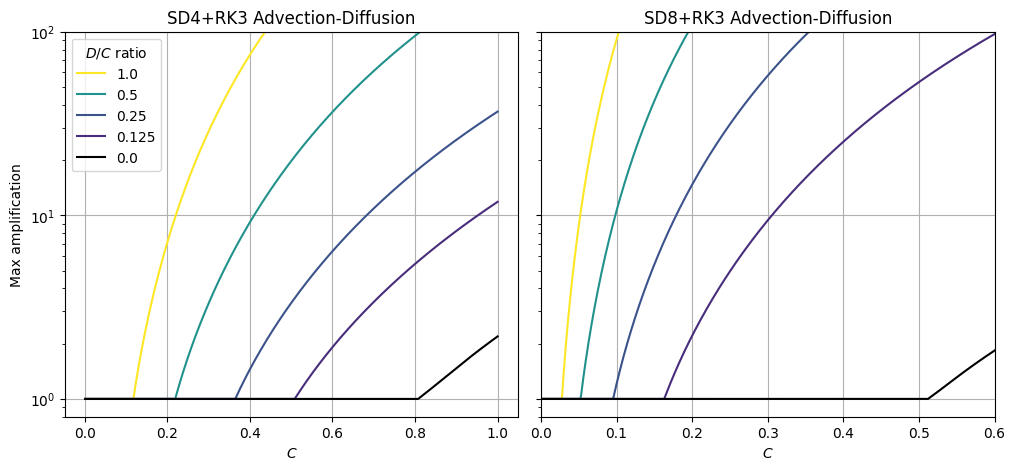

In [5]:
cfl_values = np.linspace(0.001, 1.0, 1000)
k_values = np.linspace(0, 2 * np.pi, 100)

fig, axs = plt.subplots(1, 2, sharex='col', sharey=True, figsize=(12, 5))
axs[0].set_title("SD4+RK3 Advection-Diffusion")
axs[1].set_title("SD8+RK3 Advection-Diffusion")
axs[0].set_xlabel(r"$C$")
axs[1].set_xlabel(r"$C$")
axs[0].set_ylabel("Max amplification")
axs[0].set_ylim(0.8, 100)
axs[0].set_yscale("log")
axs[1].set_xlim(0.0, 0.6)

# get jet cmap
cmap = plt.get_cmap("viridis")

for ratio in [1.0, 1/2, 1/4, 1/8, 0.0]:
    color = cmap(ratio) if ratio > 0 else "black"
    plot_amplification_values(axs[0], 3, k_values, cfl_values, "sd", "ssprk3", "both", lambda cfl_val: ratio * cfl_val, color=color, label=f"{ratio}")
    plot_amplification_values(axs[1], 7, k_values, cfl_values, "sd", "ssprk3", "both", lambda cfl_val: ratio * cfl_val, color=color, label=f"{ratio}")

# legend with title
axs[0].legend(title=r"$D/C$ ratio")
for ax in axs.flat:
    ax.grid()

plt.subplots_adjust(hspace=0.2, wspace=0.05)

plt.savefig("../out/advection-diffusion_stability_SD.pdf", bbox_inches="tight")

In [3]:
def compute_amplification_mesh(p, k_values, scheme, rk, operator, coeff_C_values, coeff_D_values):
    out = np.empty((len(coeff_D_values), len(coeff_C_values)))
    for i, coeff_D in enumerate(coeff_D_values):
        for j, coeff_C in enumerate(coeff_C_values):
            out[i, j] = compute_rk_amplification(p, k_values, scheme, rk, operator, coeff_C=coeff_C, coeff_D=coeff_D)
    return out

def compute_first_order_amplification_mesh(coeff_C_values, coeff_D_values):
    out = np.empty((len(coeff_D_values), len(coeff_C_values)))
    for i, coeff_D in enumerate(coeff_D_values):
        for j, coeff_C in enumerate(coeff_C_values):
            out[i, j] = coeff_C + 2 * coeff_D
    return out


In [4]:
def get_smallest_cell_rescale(p):
    _, fps = compute_solution_and_flux_point_coordinates(p)
    return (fps[1] - fps[0])

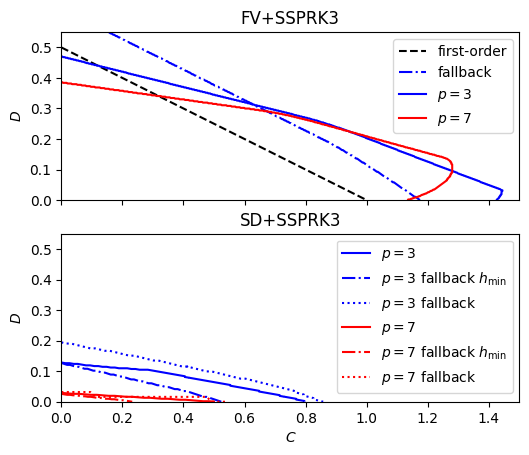

In [5]:
fig, axs = plt.subplots(2, 1, sharex=True, sharey=True)
axs[1].set_xlabel(r"$C$")
axs[0].set_xlim(0.0, 1.5)
axs[0].set_ylim(0.0, 0.55)
for ax in axs.flatten():
    ax.set_aspect("equal")
    ax.set_ylabel(r"$D$")

k_values = np.linspace(0.0, 2 * np.pi, 100)

axs[0].set_title("FV+SSPRK3")

coeff_C_values = np.linspace(0.0, 1.5, 512)
coeff_D_values = np.linspace(0.0, 0.55, 256)
amplification = compute_first_order_amplification_mesh(coeff_C_values, coeff_D_values)
axs[0].contour(coeff_C_values, coeff_D_values, amplification, levels=[1.0], colors='black', linestyles='--')

amplification = compute_amplification_mesh(1, k_values, "fv", "ssprk3", "both", coeff_C_values, coeff_D_values)
axs[0].contour(coeff_C_values, coeff_D_values, amplification, levels=[1.0], colors='blue', linestyles='dashdot')

amplification = compute_amplification_mesh(3, k_values, "fv", "ssprk3", "both", coeff_C_values, coeff_D_values)
axs[0].contour(coeff_C_values, coeff_D_values, amplification, levels=[1.0], colors='blue')

amplification = compute_amplification_mesh(7, k_values, "fv", "ssprk3", "both", coeff_C_values, coeff_D_values)
axs[0].contour(coeff_C_values, coeff_D_values, amplification, levels=[1.0], colors='red')

legend_handles = [
    plt.Line2D([], [], color='black', linestyle='--', label="first-order"),
    plt.Line2D([], [], color='blue', linestyle='dashdot', label="fallback"),
    plt.Line2D([], [], color='blue', label=r"$p=3$"),
    plt.Line2D([], [], color='red', label=r"$p=7$"),
]
axs[0].legend(handles=legend_handles)

axs[1].set_title("SD+SSPRK3")

coeff_C_values = np.linspace(0.0, 0.6, 64)
coeff_D_values = np.linspace(0.0, 0.2, 64)
rescale = get_smallest_cell_rescale(3)
amplification = compute_amplification_mesh(1, k_values, "fv", "ssprk3", "both", coeff_C_values / rescale, coeff_D_values / (rescale ** 2))
axs[1].contour(coeff_C_values, coeff_D_values, amplification, levels=[1.0], colors='blue', linestyles='dashdot')

coeff_C_values = np.linspace(0.0, 0.3, 32)
coeff_D_values = np.linspace(0.0, 0.05, 32)
rescale = get_smallest_cell_rescale(7)
amplification = compute_amplification_mesh(1, k_values, "fv", "ssprk3", "both", coeff_C_values / rescale, coeff_D_values / (rescale ** 2))
axs[1].contour(coeff_C_values, coeff_D_values, amplification, levels=[1.0], colors='red', linestyles='dashdot')

coeff_C_values = np.linspace(0.0, 1.0, 64)
coeff_D_values = np.linspace(0.0, 0.25, 64)
amplification = compute_amplification_mesh(3, k_values, "sd_fallback", "ssprk3", "both", coeff_C_values, coeff_D_values)
axs[1].contour(coeff_C_values, coeff_D_values, amplification, levels=[1.0+1e-14], colors='blue', linestyles='dotted')

coeff_C_values = np.linspace(0.0, 1.0, 64)
coeff_D_values = np.linspace(0.0, 1.0, 64)
amplification = compute_amplification_mesh(7, k_values, "sd_fallback", "ssprk3", "both", coeff_C_values, coeff_D_values)
axs[1].contour(coeff_C_values, coeff_D_values, amplification, levels=[1.0+1e-14], colors='red', linestyles='dotted')

coeff_C_values = np.linspace(0.0, 0.85, 64)
coeff_D_values = np.linspace(0.0, 0.15, 64)
amplification = compute_amplification_mesh(3, k_values, "sd", "ssprk3", "both", coeff_C_values, coeff_D_values)
axs[1].contour(coeff_C_values, coeff_D_values, amplification, levels=[1.0+1e-12], colors='blue')

coeff_C_values = np.linspace(0.0, 0.6, 32)
coeff_D_values = np.linspace(0.0, 0.05, 32)
amplification = compute_amplification_mesh(7, k_values, "sd", "ssprk3", "both", coeff_C_values, coeff_D_values)
axs[1].contour(coeff_C_values, coeff_D_values, amplification, levels=[1.0+1e-12], colors='red')

legend_handles = [
    plt.Line2D([], [], color='blue', label=r"$p=3$"),
    plt.Line2D([], [], color='blue', label=r"$p=3$ fallback $h_{\min}$", linestyle='dashdot'),
    plt.Line2D([], [], color='blue', label=r"$p=3$ fallback", linestyle='dotted'),
    plt.Line2D([], [], color='red', label=r"$p=7$"),
    plt.Line2D([], [], color='red', label=r"$p=7$ fallback $h_{\min}$", linestyle='dashdot'),
    plt.Line2D([], [], color='red', label=r"$p=7$ fallback", linestyle='dotted'),
]
axs[1].legend(handles=legend_handles)

fig.savefig("../out/stabililty.pdf")

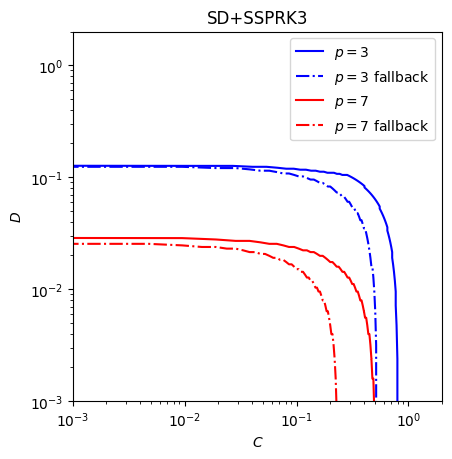

In [ ]:
fig, ax = plt.subplots()
ax.set_xlabel(r"$C$")

ax.set_xlim(1e-3, 2)
ax.set_ylim(1e-3, 2)
ax.set_aspect("equal")
ax.set_yscale("log")
ax.set_xscale("log")
ax.set_ylabel(r"$D$")

k_values = np.linspace(0.0, 2 * np.pi, 100)

ax.set_title("SD+SSPRK3")

coeff_C_values = np.linspace(0.0, 0.6, 64)
coeff_D_values = np.linspace(0.0, 0.2, 64)
rescale = get_smallest_cell_rescale(3)
amplification = compute_amplification_mesh(1, k_values, "fv", "ssprk3", "both", coeff_C_values / rescale, coeff_D_values / (rescale ** 2))
ax.contour(coeff_C_values, coeff_D_values, amplification, levels=[1.0], colors='blue', linestyles='dashdot')

# coeff_C_values = np.linspace(0.0, 0.3, 64)
# coeff_D_values = np.linspace(0.0, 0.05, 64)
# rescale = get_smallest_cell_rescale(7)
# amplification = compute_amplification_mesh(1, k_values, "fv", "ssprk3", "both", coeff_C_values / rescale, coeff_D_values / (rescale ** 2))
# ax.contour(coeff_C_values, coeff_D_values, amplification, levels=[1.0], colors='red', linestyles='dashdot')

# coeff_C_values = np.linspace(0.0, 0.85, 64)
# coeff_D_values = np.linspace(0.0, 0.15, 64)
# amplification = compute_amplification_mesh(3, k_values, "sd", "ssprk3", "both", coeff_C_values, coeff_D_values)
# ax.contour(coeff_C_values, coeff_D_values, amplification, levels=[1.0+1e-12], colors='blue')

# coeff_C_values = np.linspace(0.0, 0.6, 64)
# coeff_D_values = np.linspace(0.0, 0.05, 64)
# amplification = compute_amplification_mesh(7, k_values, "sd", "ssprk3", "both", coeff_C_values, coeff_D_values)
# ax.contour(coeff_C_values, coeff_D_values, amplification, levels=[1.0+1e-12], colors='red')

legend_handles = [
    plt.Line2D([], [], color='blue', label=r"$p=3$"),
    plt.Line2D([], [], color='blue', label=r"$p=3$ fallback", linestyle='dashdot'),
    plt.Line2D([], [], color='red', label=r"$p=7$"),
    plt.Line2D([], [], color='red', label=r"$p=7$ fallback", linestyle='dashdot'),
]
ax.legend(handles=legend_handles)

fig.savefig("../out/stabililty_sd_zoom.pdf")